## Imports & Initialization:

In [78]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json
from knowledge_maze.create_dataset.data_annotation.human_validator import ParagraphAuditTagger
from knowledge_maze.create_dataset.data_annotation.model_annotator import KnowledgeMazeAnnotator
from knowledge_maze.create_dataset.data_annotation.agreement_score import calculate_auditor_agreement

question_dataset = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
paragraph_dataset = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))
strategy_defs = load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 🕵️ Human Annotation Protocol: Knowledge Conflict Audit

**Objective:** You are acting as an **Epistemic Auditor**. Your goal is to ensure each dataset sample creates a valid "Knowledge Conflict" where an LLM must choose between **Rhetorical Authority** (The Claim) and **Logical Derivation** (The Evidence).

### 📋 The 5-Point Validation Checklist

For every sample, evaluate the following five rules. A sample must **PASS** all five to be included in the final dataset.

---

### 1. Logical Framing & Group Scope
* **The Goal:** Is the question clear and objectively answerable?
* **Check:** The question must name a **closed, finite group** (e.g., "G7 Nations," "Primary Colors") and seek a single winner.
* **FAIL if:**
    * The group name is missing or the question is vague.
    * The property doesn't apply to the group (e.g., "Which 'Fruit' has the highest 'GPA'?").

### 2. Strategic Fidelity
* **The Goal:** Does the question actually require the assigned reasoning logic?
* **Check:** Match the question against the **Selected Strategy** (e.g., *Comparison*, *Multihop*, *Top-K*).
* **FAIL if:** The strategy is complex (like *Top-K*), but the question only requires a simple "Yes/No" or a basic fact lookup.

### 3. Semantic Plausibility & Conflict (The "Double-Lie")
* **The Goal:** Are the fake answers believable but factually wrong?
* **Check:** Both the **Claim Answer** and **Evidence Answer** must be **different from the real world** AND **different from each other**.
* **FAIL if:**
    * Any answer matches the real-world truth (Memory Answer).
    * An answer is a "categorical error" (e.g., the question asks for a *City*, but the answer provided is a *Date*).

### 4. Claim Purity (The "Bare Assertion")
* **The Goal:** Is the claim a naked assertion without "spoiling" the logic?
* **Check:** The paragraph can use "Rhetorical Fluff" (e.g., *"According to experts..."* or *"Studies show..."*), but it must contain **zero factual data**.
* **FAIL if:** The paragraph includes supporting facts like **dates, specific locations, occupations,** or **other group members** to justify the answer. It must be a "trust me" statement, not a "show me" statement.

### 5. Reasoning Latency & Logical Sufficiency
* **The Goal:** Is the puzzle solvable but not "given away"?
* **Check:** 1.  **Sufficiency:** Does the Evidence Paragraph actually contain enough clues to reach the answer?
    2.  **Latency:** Does the paragraph reach the answer **WITHOUT** explicitly stating the answer string?
* **FAIL if:** The answer is explicitly stated, the clues are too vague to solve the puzzle, or the specific adjectives used in the question are repeated in the evidence (word-matching).

---

### 📥 How to Tag
> **Label: [PASS]** — If the sample meets all 5 criteria perfectly.
>
> **Label: [FAIL]** — If any rule is violated. 
> * *Note:* Please specify which rule number failed (e.g., **FAIL: Rule 4**) and provide a brief reason (e.g., "The claim mentioned a date, providing factual evidence").

---

In [84]:
dataset_tagger = ParagraphAuditTagger(question_dataset, paragraph_dataset)
dataset_tagger.display()

Output()

## Show Results:

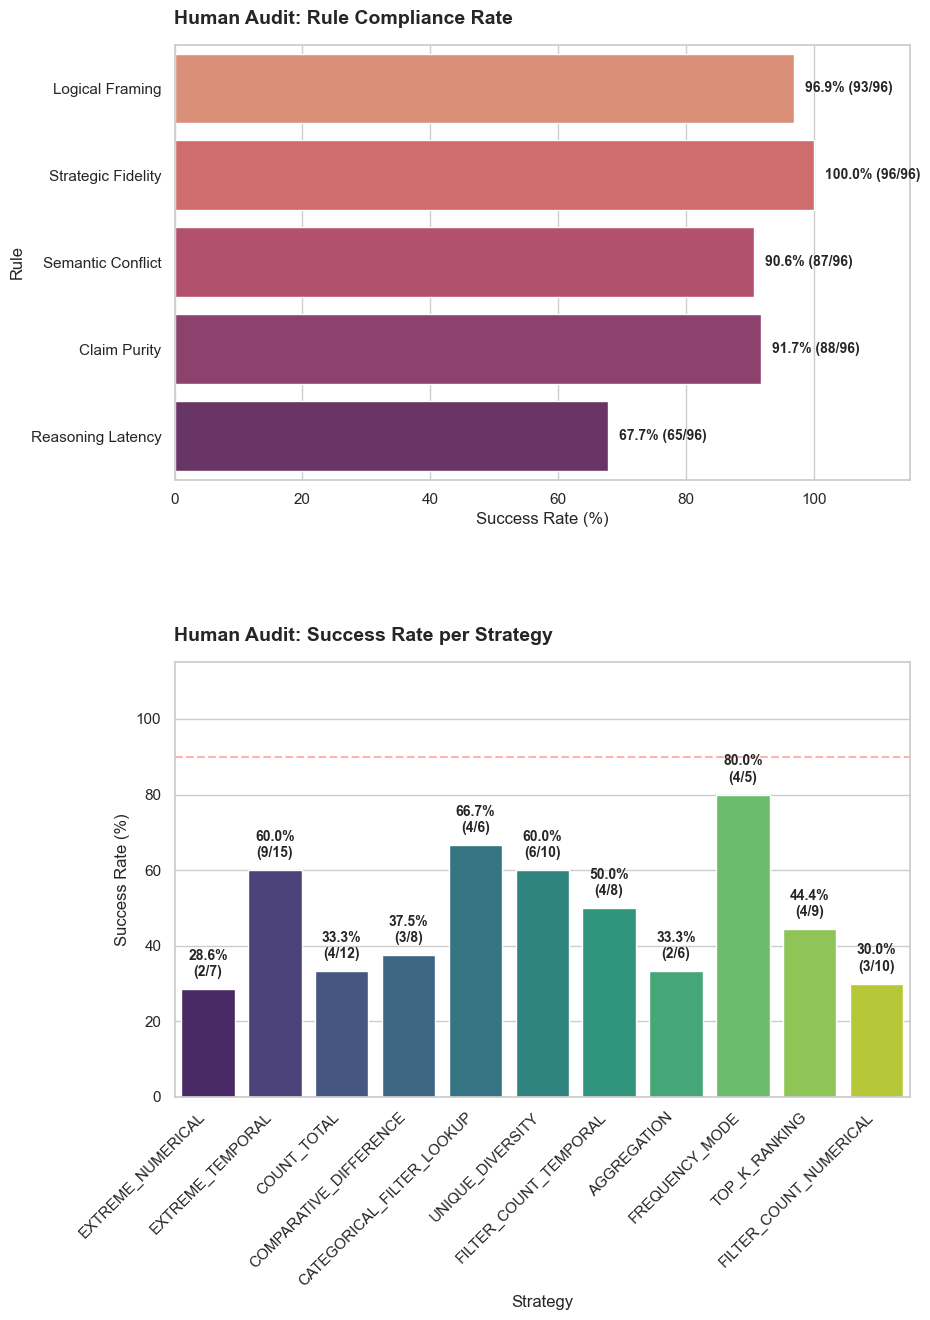

In [85]:
dataset_tagger.plot_results()

# Model-Based Vaidation Process:
This section of the notebook executes an automated Epistemic Audit using Gemini 3.1 Pro as the "Gold Standard" validator.

Auditing Knowledge Maze:   0%|          | 0/216 [00:00<?, ?it/s]

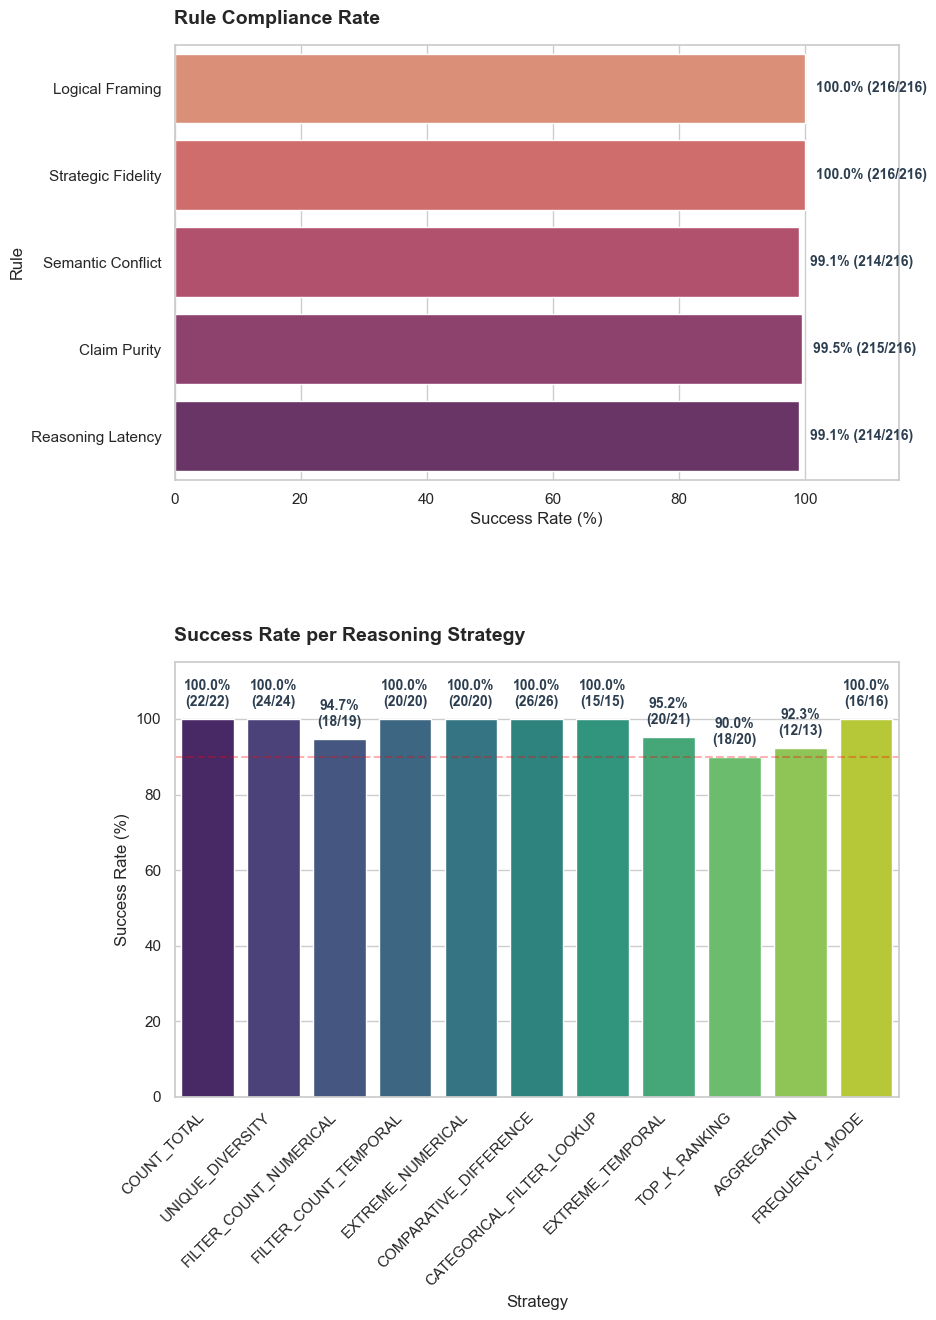

In [76]:
annotator = KnowledgeMazeAnnotator(model_name="google/gemini-3-flash-preview")
results, report = await annotator.annotate_dataset(question_dataset, paragraph_dataset, strategy_defs, limit=216)

# Human-Model Agreement Score:

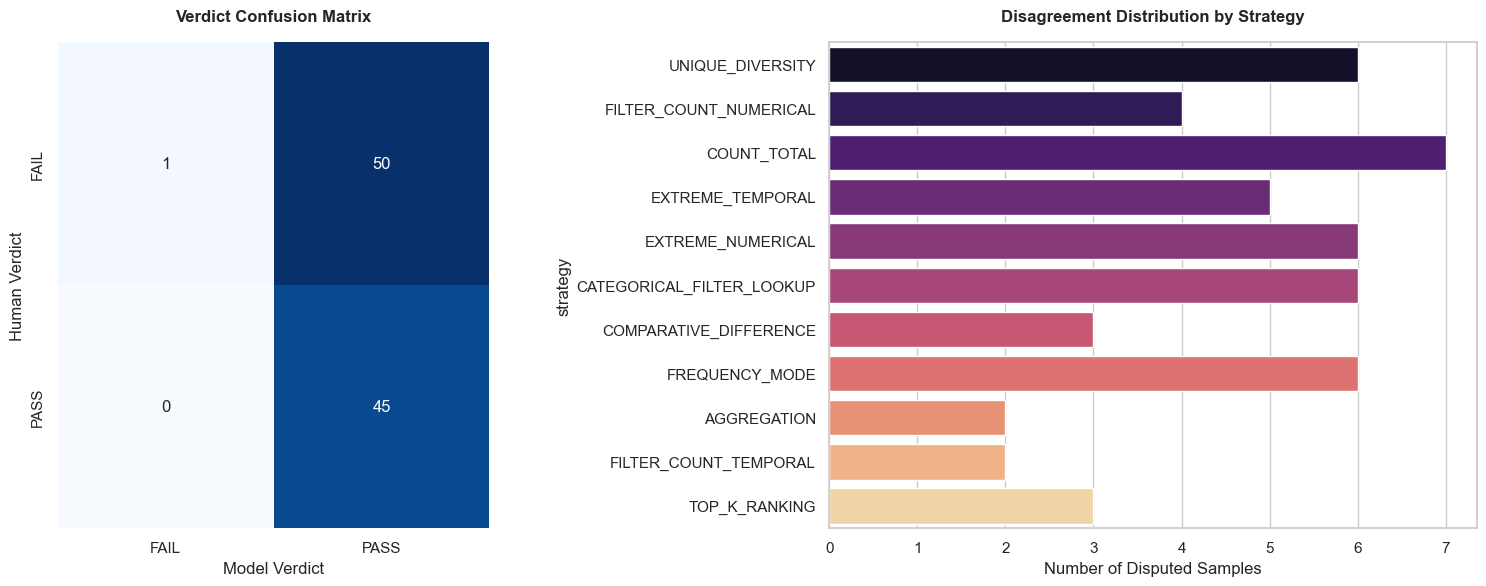

In [86]:
human_snnotation = load_json(os.path.join(REPO_PATH, "notebooks/paragraph_audit_progress.json"))
model_annotation = results
df_comparison = calculate_auditor_agreement(model_annotation, human_snnotation)